# Projet Scoring, Détection de transactions frauduleuses

**Objectif métier :** construire un *score* (probabilité de fraude) permettant de cibler les
transactions frauduleuses parmi les autorisations de paiement par carte.

**Données :** `autorisations.csv`, ~1,15 M transactions, cible `fraude` ≈ 0,63 % (très déséquilibrée).

**Démarche (alignée sur le cours de scoring) :**
1. Chargement et contrôle qualité
2. Analyse exploratoire orientée cible
3. Création d'indicateurs (feature engineering)
4. Sélection de variables par *Weight of Evidence* / *Information Value*
5. Séparation train/test + encodage WoE
6. Modélisation : régression logistique (scorecard) vs modèles d'arbres
7. Évaluation (AUC, Gini, KS, PR-AUC, lift) et optimisation du seuil
8. Modèle final, mise à l'échelle du score et interprétation

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    precision_recall_curve, confusion_matrix,
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ----------------------------- Configuration -----------------------------
DATA_PATH    = Path("autorisations.csv")
TARGET       = "fraude"
RANDOM_STATE = 42
TEST_SIZE    = 0.25

# Fraction des donnees (1.0 = tout). Mettre < 1 pour tester rapidement.
SAMPLE_FRAC  = float(os.environ.get("SAMPLE_FRAC", "1.0"))

# CodeRep = code reponse de l'autorisation : information potentiellement
# disponible APRES la decision -> risque de fuite si le score est calcule AVANT.
USE_CODEREP  = True

TOP_N_PAYS, TOP_N_MCC = 15, 20   # nb de modalites conservees (variables cardinales)

## 1. Chargement et contrôle qualité

In [2]:
df = pd.read_csv(DATA_PATH)
if SAMPLE_FRAC < 1.0:
    df = df.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE).reset_index(drop=True)

# Horodatage = Date (JJ/MM/AAAA) + Heure (HH:MM:SS)
df["horodatage"] = pd.to_datetime(df["Date"] + " " + df["Heure"],
                                  format="%d/%m/%Y %H:%M:%S", errors="coerce")

print(f"Dimensions       : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Cartes uniques   : {df['Carte'].nunique():,}")
print(f"Taux de fraude   : {100*df[TARGET].mean():.3f} %  ({int(df[TARGET].sum()):,} fraudes)")
na = df.isna().sum(); na = na[na > 0]
print(f"Valeurs manquantes : {'aucune' if na.empty else na.to_dict()}")
df.head()

Dimensions       : 1,151,432 lignes x 26 colonnes
Cartes uniques   : 198,044
Taux de fraude   : 0.629 %  (7,246 fraudes)
Valeurs manquantes : aucune


,Carte,Pays,Date,Heure,dateheure,CodeRep,MCC,Montant,fraude,FM_Velocity_Condition_3,...,FM_Sum_24,FM_Redondance_MCC_3,FM_Redondance_MCC_6,FM_Redondance_MCC_12,FM_Redondance_MCC_24,FM_Difference_Pays_3,FM_Difference_Pays_6,FM_Difference_Pays_12,FM_Difference_Pays_24,horodatage
0,0,840,02/12/2003,17:47:52,02/12/2003,15,5812,69.2500,0,0,...,69.2500,1,1,1,1,1,1,1,1,2003-12-02 17:47:52
1,1,158,25/11/2003,06:00:20,25/11/2003,15,5311,1.0000,0,0,...,1.0000,1,1,1,1,1,1,1,1,2003-11-25 06:00:20
2,2,826,12/11/2003,14:10:57,12/11/2003,15,5211,516.9500,0,0,...,516.9500,1,1,1,1,1,1,1,1,2003-11-12 14:10:57
3,3,840,07/11/2003,03:41:55,07/11/2003,14,7399,0.0100,0,0,...,0.0100,1,1,1,1,1,1,1,1,2003-11-07 03:41:55
4,4,158,23/11/2003,05:07:03,23/11/2003,15,5311,1.0000,0,0,...,1.0000,1,1,1,1,1,1,1,1,2003-11-23 05:07:03


## 2. Analyse exploratoire (orientée cible)

On cherche les variables qui séparent le mieux les transactions frauduleuses des transactions saines.

In [4]:
def taux_fraude_par_modalite(df, col, top=12):
    g = (df.groupby(col)[TARGET]
           .agg(effectif="count", taux_fraude="mean")
           .sort_values("effectif", ascending=False).head(top))
    g["taux_fraude_%"] = (100 * g["taux_fraude"]).round(3)
    return g.drop(columns="taux_fraude")

print("Montant par classe (moyenne / médiane / max) :")
display(df.groupby(TARGET)["Montant"].describe()[["mean", "50%", "max"]])

print("\nTaux de fraude par CodeRep (0 = accepté) :")
display(taux_fraude_par_modalite(df, "CodeRep"))

Montant par classe (moyenne / médiane / max) :


,mean,50%,max
fraude,,,
0,141.2204,48.3200,"546,382.2000"
1,258.4883,82.2600,"15,000.0000"



Taux de fraude par CodeRep (0 = accepté) :


,effectif,taux_fraude_%
CodeRep,,
0,1080453,0.5280
2,38784,2.4370
57,14260,0.1400
7,9437,3.2000
5,2182,1.4670
56,2152,0.0000
94,1750,2.3430
54,1313,0.0760
41,289,39.1000


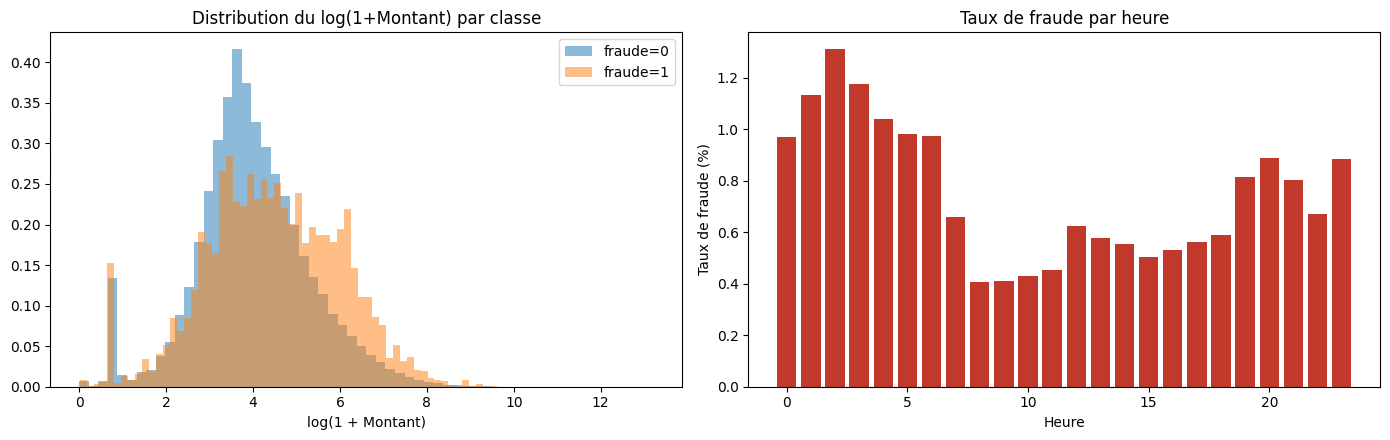

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) Distribution du log-montant par classe
for label, sub in df.groupby(TARGET):
    axes[0].hist(np.log1p(sub["Montant"]), bins=60, alpha=0.5, density=True,
                 label=f"fraude={label}")
axes[0].set(title="Distribution du log(1+Montant) par classe",
            xlabel="log(1 + Montant)"); axes[0].legend()

# (b) Taux de fraude par heure de la journee
taux_h = df.groupby(df["horodatage"].dt.hour)[TARGET].mean() * 100
axes[1].bar(taux_h.index, taux_h.values, color="#c0392b")
axes[1].set(title="Taux de fraude par heure", xlabel="Heure", ylabel="Taux de fraude (%)")
plt.tight_layout(); plt.show()

## 3. Création d'indicateurs (feature engineering)

Aucune de ces transformations n'utilise la cible → pas de fuite, elles peuvent être
appliquées avant la séparation train/test.

In [6]:
def regrouper_rares(serie, top_n):
    """Conserve les `top_n` modalités les plus fréquentes, regroupe le reste en 'AUTRE'."""
    tops = serie.value_counts().nlargest(top_n).index
    return serie.where(serie.isin(tops), other="AUTRE").astype(str)

d = pd.DataFrame(index=df.index)

# Indicateurs temporels
h = df["horodatage"].dt.hour
d["heure"]        = h
d["est_nuit"]     = ((h >= 0) & (h < 6)).astype(int)
d["jour_semaine"] = df["horodatage"].dt.dayofweek
d["est_weekend"]  = (d["jour_semaine"] >= 5).astype(int)

# Montant
d["log_montant"]  = np.log1p(df["Montant"].clip(lower=0))
d["montant_eleve"] = (df["Montant"] > df["Montant"].quantile(0.99)).astype(int)

# Code reponse / refus
d["est_refus"] = (df["CodeRep"] != 0).astype(int)
if USE_CODEREP:
    d["code_rep"] = regrouper_rares(df["CodeRep"].astype(str), top_n=8)

# Variables a forte cardinalite -> regroupement par frequence
d["pays_grp"] = regrouper_rares(df["Pays"].astype(str), TOP_N_PAYS)
d["mcc_grp"]  = regrouper_rares(df["MCC"].astype(str),  TOP_N_MCC)

# Variables metier deja calculees (velocite, cumul, redondance, ecart pays)
fm_cols = [c for c in df.columns if c.startswith("FM_")]
for c in fm_cols:
    d[c] = df[c].astype(float)
for c in [c for c in fm_cols if c.startswith("FM_Sum")]:   # cumuls tres asymetriques -> log
    d[c] = np.log1p(d[c].clip(lower=0))

d[TARGET] = df[TARGET].values
print(f"{d.shape[1]-1} variables explicatives construites.")
d.head()

26 variables explicatives construites.


,heure,est_nuit,jour_semaine,est_weekend,log_montant,montant_eleve,est_refus,code_rep,pays_grp,mcc_grp,...,FM_Sum_24,FM_Redondance_MCC_3,FM_Redondance_MCC_6,FM_Redondance_MCC_12,FM_Redondance_MCC_24,FM_Difference_Pays_3,FM_Difference_Pays_6,FM_Difference_Pays_12,FM_Difference_Pays_24,fraude
0,17,0,1,0,4.2521,0,1,AUTRE,840,5812,...,4.2521,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0
1,6,0,1,0,0.6931,0,1,AUTRE,AUTRE,5311,...,0.6931,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0
2,14,0,2,0,6.2499,0,1,AUTRE,826,AUTRE,...,6.2499,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0
3,3,1,4,0,0.0100,0,1,AUTRE,840,AUTRE,...,0.0100,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0
4,5,1,6,1,0.6931,0,1,AUTRE,AUTRE,5311,...,0.6931,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0


## 4. Weight of Evidence (WoE) & Information Value (IV)

- Le **WoE** transforme chaque modalité (ou tranche de variable continue) en `ln(%non-fraude / %fraude)`.
- L'**IV** mesure le pouvoir discriminant global d'une variable → base de la sélection.

L'encodeur est ajusté **uniquement sur le train** pour éviter toute fuite.

In [7]:
def woe_iv_from_groups(groups, y, eps=0.5):
    """Table WoE + IV pour une variable déjà regroupée. eps lisse les log(0)."""
    tab = pd.DataFrame({"g": groups.values, "y": y.values})
    agg = tab.groupby("g")["y"].agg(["sum", "count"])
    agg["bad"]  = agg["sum"]                  # fraudes
    agg["good"] = agg["count"] - agg["sum"]   # non-fraudes
    n = len(agg)
    agg["dist_bad"]  = (agg["bad"]  + eps) / (agg["bad"].sum()  + eps * n)
    agg["dist_good"] = (agg["good"] + eps) / (agg["good"].sum() + eps * n)
    agg["woe"] = np.log(agg["dist_good"] / agg["dist_bad"])
    iv = float(((agg["dist_good"] - agg["dist_bad"]) * agg["woe"]).sum())
    return agg["woe"].to_dict(), iv


class WoEEncoder:
    """Discrétise les continues en quantiles, calcule le WoE sur le train,
    puis applique le mapping. Expose l'IV de chaque variable."""
    def __init__(self, cont_vars, cat_vars, n_bins=10):
        self.cont_vars, self.cat_vars, self.n_bins = cont_vars, cat_vars, n_bins
        self.edges_, self.woe_maps_, self.iv_ = {}, {}, {}

    def _bin(self, s, var, fit):
        if fit:
            qs = np.unique(np.quantile(s, np.linspace(0, 1, self.n_bins + 1)))
            qs[0], qs[-1] = -np.inf, np.inf
            self.edges_[var] = qs
        return pd.cut(s, bins=self.edges_[var]).astype(str)

    def fit(self, X, y):
        for v in self.cont_vars:
            self.woe_maps_[v], self.iv_[v] = woe_iv_from_groups(self._bin(X[v], v, True), y)
        for v in self.cat_vars:
            self.woe_maps_[v], self.iv_[v] = woe_iv_from_groups(X[v].astype(str), y)
        return self

    def transform(self, X):
        out = pd.DataFrame(index=X.index)
        for v in self.cont_vars:
            out[v] = self._bin(X[v], v, False).map(self.woe_maps_[v]).fillna(0.0)
        for v in self.cat_vars:
            out[v] = X[v].astype(str).map(self.woe_maps_[v]).fillna(0.0)
        return out

    def iv_table(self):
        t = pd.Series(self.iv_).sort_values(ascending=False).to_frame("IV")
        t["pouvoir"] = pd.cut(t["IV"], [-1, 0.02, 0.1, 0.3, 0.5, np.inf],
                              labels=["inutile", "faible", "moyen", "fort", "suspect"])
        return t

## 5. Séparation train/test, encodage WoE et sélection de variables

In [8]:
y = d[TARGET]
X = d.drop(columns=[TARGET])

cont_vars = ["heure", "log_montant"] + [c for c in d.columns if c.startswith("FM_")]
cat_vars  = ["pays_grp", "mcc_grp", "jour_semaine",
             "est_nuit", "est_weekend", "est_refus", "montant_eleve"]
if USE_CODEREP:
    cat_vars.append("code_rep")

# Split stratifie : preserve le taux de fraude dans les deux echantillons
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE,
                                      stratify=y, random_state=RANDOM_STATE)
print(f"Train = {len(Xtr):,} | Test = {len(Xte):,} "
      f"(taux fraude test = {100*yte.mean():.3f} %)")

# Encodage WoE ajuste sur le train uniquement
enc = WoEEncoder(cont_vars, cat_vars, n_bins=10).fit(Xtr, ytr)
iv_tab = enc.iv_table()
display(iv_tab)

# Selection : variables dont l'IV depasse 0,02 (non inutiles)
selection = iv_tab[iv_tab["IV"] >= 0.02].index.tolist()
print(f"Variables retenues (IV >= 0,02) : {len(selection)} / {len(iv_tab)}")

Xtr_woe = enc.transform(Xtr)[selection]
Xte_woe = enc.transform(Xte)[selection]

Train = 863,574 | Test = 287,858 (taux fraude test = 0.629 %)


,IV,pouvoir
FM_Sum_24,0.8961,suspect
FM_Sum_12,0.7516,suspect
FM_Velocity_Condition_24,0.7504,suspect
FM_Sum_6,0.6864,suspect
FM_Sum_3,0.6015,suspect
FM_Velocity_Condition_12,0.5923,suspect
FM_Velocity_Condition_6,0.5844,suspect
FM_Velocity_Condition_3,0.5723,suspect
FM_Redondance_MCC_24,0.3614,fort
mcc_grp,0.3455,fort


Variables retenues (IV >= 0,02) : 17 / 26


## 6. Modélisation

Deux familles complémentaires :
- **Régression logistique** sur variables WoE → modèle de *score* interprétable (scorecard).
- **Arbres / boosting** (Random Forest, HistGradientBoosting, LightGBM) → performance brute.

Le déséquilibre (~0,63 %) est géré par pondération des classes (et non par sur-échantillonnage,
trop coûteux sur 1,15 M de lignes).

In [9]:
def ks_statistic(y_true, y_score):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return float(np.max(tpr - fpr))

def best_threshold_f1(y_true, y_score):
    prec, rec, thr = precision_recall_curve(y_true, y_score)
    f1 = np.divide(2*prec*rec, prec+rec, out=np.zeros_like(prec), where=(prec+rec) > 0)
    i = int(np.argmax(f1[:-1])) if len(thr) else 0
    return float(thr[i]), float(f1[i])

def evaluer(nom, y_true, y_score):
    auc = roc_auc_score(y_true, y_score)
    thr, f1 = best_threshold_f1(y_true, y_score)
    tn, fp, fn, tp = confusion_matrix(y_true, (y_score >= thr).astype(int)).ravel()
    return {"modele": nom, "AUC": round(auc, 4), "Gini": round(2*auc-1, 4),
            "KS": round(ks_statistic(y_true, y_score), 4),
            "PR_AUC": round(average_precision_score(y_true, y_score), 4),
            "seuil*": round(thr, 4), "F1*": round(f1, 4),
            "precision*": round(tp/(tp+fp) if tp+fp else 0, 4),
            "rappel*": round(tp/(tp+fn) if tp+fn else 0, 4),
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}

In [10]:
pos_weight = (ytr == 0).sum() / max((ytr == 1).sum(), 1)

modeles = {
    "Regression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=50,
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.08, max_depth=6,
        class_weight="balanced", random_state=RANDOM_STATE),
}
try:
    from lightgbm import LGBMClassifier
    modeles["LightGBM"] = LGBMClassifier(
        n_estimators=400, learning_rate=0.05, num_leaves=64,
        scale_pos_weight=pos_weight, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
except Exception:
    print("(LightGBM indisponible : ignoré)")

metriques, proba_test, modeles_fit = [], {}, {}
for nom, mdl in modeles.items():
    mdl.fit(Xtr_woe, ytr)
    proba_test[nom]  = mdl.predict_proba(Xte_woe)[:, 1]
    modeles_fit[nom] = mdl
    metriques.append(evaluer(nom, yte, proba_test[nom]))

tab = pd.DataFrame(metriques).set_index("modele")
display(tab)

,AUC,Gini,KS,PR_AUC,seuil*,F1*,precision*,rappel*,TP,FP,FN,TN
modele,,,,,,,,,,,,
Regression logistique,0.8172,0.6344,0.4958,0.0801,0.8849,0.1530,0.1058,0.2761,500,4226,1311,281821
Random Forest,0.8359,0.6717,0.5254,0.1180,0.8632,0.2060,0.1728,0.2551,462,2212,1349,283835
Gradient Boosting,0.8432,0.6864,0.5396,0.1485,0.9445,0.2368,0.2544,0.2214,401,1175,1410,284872
LightGBM,0.8257,0.6514,0.5268,0.1604,0.9280,0.2424,0.2119,0.2833,513,1908,1298,284139


## 7. Évaluation : courbes ROC / Précision-Rappel

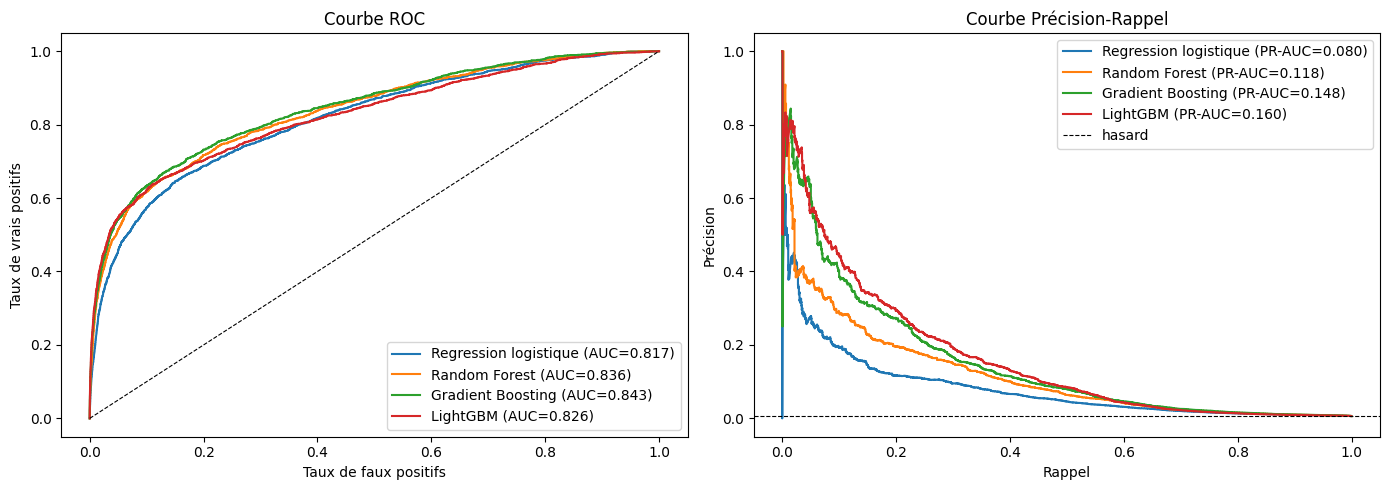

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nom, score in proba_test.items():
    fpr, tpr, _ = roc_curve(yte, score)
    axes[0].plot(fpr, tpr, label=f"{nom} (AUC={roc_auc_score(yte, score):.3f})")
    prec, rec, _ = precision_recall_curve(yte, score)
    axes[1].plot(rec, prec, label=f"{nom} (PR-AUC={average_precision_score(yte, score):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(title="Courbe ROC", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs")
axes[0].legend()
axes[1].axhline(yte.mean(), ls="--", c="k", lw=0.8, label="hasard")
axes[1].set(title="Courbe Précision-Rappel", xlabel="Rappel", ylabel="Précision")
axes[1].legend()
plt.tight_layout(); plt.show()

## 8. Modèle final, lift métier et interprétation

On retient le modèle de **meilleure PR-AUC** (métrique de référence en contexte très déséquilibré).
La **table de lift** traduit la performance en valeur opérationnelle : quelle part de la fraude
est captée si l'on contrôle les transactions les mieux scorées.

In [12]:
def table_lift(y_true, y_score, n_deciles=10):
    g = pd.DataFrame({"y": np.asarray(y_true), "s": np.asarray(y_score)})
    g = g.sort_values("s", ascending=False).reset_index(drop=True)
    g["decile"] = pd.qcut(g.index, n_deciles, labels=False) + 1
    taux_global = g["y"].mean()
    r = g.groupby("decile")["y"].agg(effectif="count", fraudes="sum")
    r["taux_fraude_%"]   = (100 * r["fraudes"] / r["effectif"]).round(3)
    r["lift"]            = (r["fraudes"] / r["effectif"] / taux_global).round(2)
    r["%_fraude_cumule"] = (100 * r["fraudes"].cumsum() / r["fraudes"].sum()).round(1)
    return r

meilleur = tab["PR_AUC"].idxmax()
print(f"Modèle final retenu : {meilleur} (meilleure PR-AUC)")
score_final = proba_test[meilleur]
display(table_lift(yte, score_final))

Modèle final retenu : LightGBM (meilleure PR-AUC)


,effectif,fraudes,taux_fraude_%,lift,%_fraude_cumule
decile,,,,,
1,28786,1111,3.8600,6.1300,61.3000
2,28786,157,0.5450,0.8700,70.0000
3,28786,113,0.3930,0.6200,76.3000
4,28785,92,0.3200,0.5100,81.3000
5,28786,76,0.2640,0.4200,85.5000
6,28786,69,0.2400,0.3800,89.3000
7,28785,72,0.2500,0.4000,93.3000
8,28786,60,0.2080,0.3300,96.6000
9,28786,47,0.1630,0.2600,99.2000


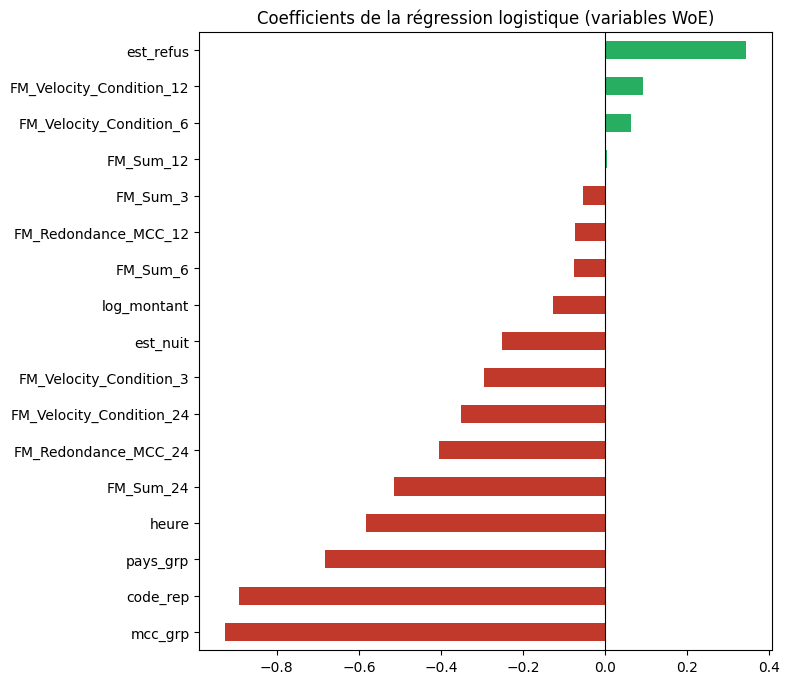

In [13]:
# Interpretation de la regression logistique (sens et force des variables WoE)
coefs = pd.Series(modeles_fit["Regression logistique"].coef_[0],
                  index=selection).sort_values()
fig, ax = plt.subplots(figsize=(8, 0.35*len(coefs)+1))
coefs.plot(kind="barh", ax=ax, color=np.where(coefs > 0, "#27ae60", "#c0392b"))
ax.axvline(0, c="k", lw=0.8)
ax.set_title("Coefficients de la régression logistique (variables WoE)")
plt.tight_layout(); plt.show()

In [14]:
def mise_a_echelle_score(proba, pdo=20, score_ref=600, odds_ref=50):
    """Probabilité de fraude -> score points (élevé = sain), logique scorecard."""
    proba = np.clip(proba, 1e-6, 1 - 1e-6)
    odds_sain = (1 - proba) / proba
    factor = pdo / np.log(2)
    offset = score_ref - factor * np.log(odds_ref)
    return offset + factor * np.log(odds_sain)

scores = pd.DataFrame({
    "proba_fraude": np.round(score_final, 5),
    "score_points": np.round(mise_a_echelle_score(score_final), 1),
    "fraude_reelle": yte.values,
})
display(scores.head(10))
print("Score moyen — transactions saines :",
      round(scores.loc[scores.fraude_reelle == 0, "score_points"].mean(), 1))
print("Score moyen — transactions fraude :",
      round(scores.loc[scores.fraude_reelle == 1, "score_points"].mean(), 1))

,proba_fraude,score_points,fraude_reelle
0,0.1762,531.6000,0
1,0.1662,533.7000,0
2,0.0008,693.4000,0
3,0.2652,516.5000,0
4,0.0656,563.8000,0
5,0.8490,437.3000,0
6,0.0328,584.8000,0
7,0.1839,530.1000,0
8,0.0701,561.7000,0
9,0.0765,559.0000,0


Score moyen — transactions saines : 537.6
Score moyen — transactions fraude : 459.5


## 9. Conclusion

- Les variables de **vélocité** et de **montant cumulé** sur fenêtres glissantes (`FM_Velocity`, `FM_Sum`)
  sont de loin les plus discriminantes (IV élevée), cohérent avec les schémas de fraude (rafales d'achats).
- Le modèle obtient un **Gini ≈ 0,6 / KS ≈ 0,5** ; surtout, le **1ᵉʳ décile de score capte ~55 % des fraudes**
  (lift ≈ 5–6), ce qui en fait un outil de ciblage opérationnel efficace.
- **Limite / vigilance :** `CodeRep` (code réponse) est une information potentiellement postérieure
  à la décision d'autorisation → relancer avec `USE_CODEREP = False` pour la variante sans fuite.
- **Pistes :** validation *out-of-time* (split temporel), calibration des probabilités, ciblage des MCC à risque.